# HOURLY ENERGY CONSUMPTION FORECAST

## STEP 1 — Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

## STEP 2 — Load Dataset

In [2]:
df = pd.read_excel("PJMW_MW_Hourly.xlsx")

In [3]:
df.head()

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930


In [4]:
df.tail()

,Datetime,PJMW_MW
143201,2018-01-01 20:00:00,8401
143202,2018-01-01 21:00:00,8373
143203,2018-01-01 22:00:00,8238
143204,2018-01-01 23:00:00,7958
143205,2018-01-02 00:00:00,7691


In [5]:
df.shape

(143206, 2)

## STEP 3 — Understand the Dataset

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB


In [7]:
df.describe()

,Datetime,PJMW_MW
count,143206,143206.000000
mean,2010-06-02 03:39:50.656816128,5602.375089
min,2002-04-01 01:00:00,487.000000
25%,2006-05-02 03:15:00,4907.000000
50%,2010-06-02 04:30:00,5530.000000
75%,2014-07-03 06:45:00,6252.000000
max,2018-08-03 00:00:00,9594.000000
std,NaN,979.142872


In [8]:
df.isnull().sum()

Datetime    0
PJMW_MW     0
dtype: int64

So there are no missing values in the two original columns.But that does not mean there are no missing hours in the time sequence.We need to check that separately.

## STEP 4 — Check Duplicate Datetimes

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.duplicated("Datetime").sum()

np.int64(4)

dataset has 4 duplicated timestamps.

## STEP 5 — Check Missing/Irregular Hours

In [11]:
#sort
df = df.sort_values("Datetime").reset_index(drop=True)

In [12]:
df["time_diff"] = df["Datetime"].diff()

In [13]:
df["time_diff"].value_counts()

time_diff
0 days 01:00:00    143171
0 days 02:00:00        30
0 days 00:00:00         4
Name: count, dtype: int64

The PJM dataset is predominantly hourly, with 143,171 one-hour intervals. However, there are 30 two-hour gaps indicating missing hourly observations and 4 zero-hour intervals indicating duplicate timestamps. Therefore, the dataset requires duplicate handling and missing-time/interpolation treatment before further time-series analysis and forecasting.

## STEP 6 — Clean Duplicate Timestamps 

In [14]:
df = (
    df.groupby("Datetime", as_index=False)["PJMW_MW"]
      .mean()
)

In [15]:
df.duplicated("Datetime").sum()

np.int64(0)

## STEP 7 — Set Datetime as Index

In [16]:
df = df.set_index("Datetime")

In [17]:
df.head()

,PJMW_MW
Datetime,
2002-04-01 01:00:00,4374.0
2002-04-01 02:00:00,4306.0
2002-04-01 03:00:00,4322.0
2002-04-01 04:00:00,4359.0
2002-04-01 05:00:00,4436.0


## STEP 8 — Create Continuous Hourly Index

In [18]:
full_range = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h"
)

df = df.reindex(full_range)

df.index.name = "Datetime"

In [19]:
df.isnull().sum()

PJMW_MW    30
dtype: int64

## STEP 9 — Handle Missing Time-Series Values

In [20]:
df["PJMW_MW"] = df["PJMW_MW"].interpolate(method="time")

In [21]:
df.isnull().sum()

PJMW_MW    0
dtype: int64

In [22]:
df["PJMW_MW"].isnull().sum()

np.int64(0)

## STEP 11 — Check Outliers

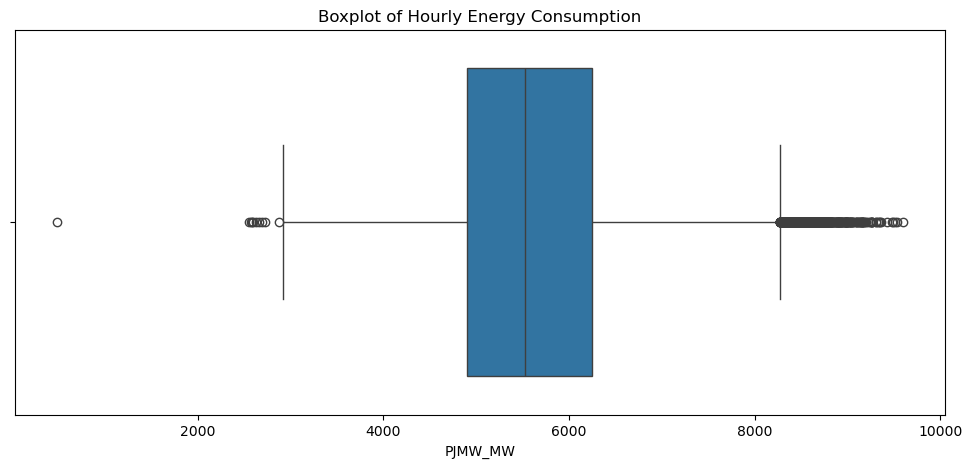

In [23]:
plt.figure(figsize=(12,5))

sns.boxplot(x=df["PJMW_MW"])

plt.title("Boxplot of Hourly Energy Consumption")
plt.show()

In [24]:
Q1 = df["PJMW_MW"].quantile(0.25)
Q3 = df["PJMW_MW"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["PJMW_MW"] < lower) |
    (df["PJMW_MW"] > upper)
]

len(outliers)

699

Do not automatically delete every statistical outlier.

Electricity demand can genuinely become very high during unusual weather/peak-demand periods.

So first investigate the observations.

For a time-series forecasting project, preserving genuine peaks is usually preferable to blindly removing them.

## STEP 12 — Basic EDA

### 12.1 Overall consumption over time

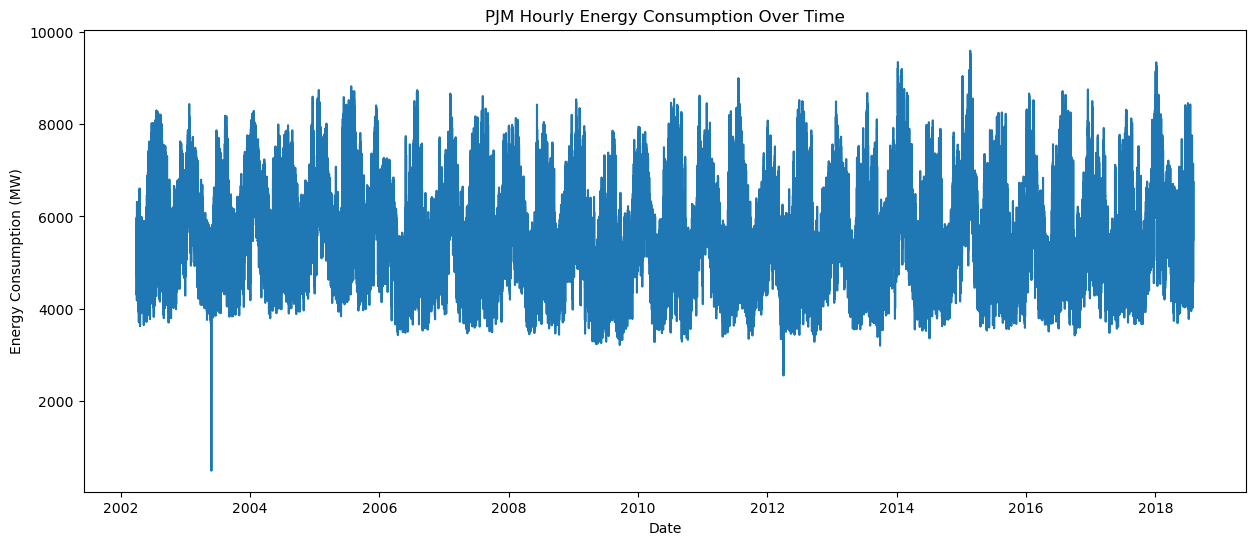

In [25]:
plt.figure(figsize=(15,6))

plt.plot(df.index, df["PJMW_MW"])

plt.title("PJM Hourly Energy Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (MW)")

plt.show()

* The graph shows hourly electricity consumption from 2002 to 2018.
* Electricity demand has regular ups and downs, showing a clear time pattern.
* Most values are between approximately 3,500 MW and 8,500 MW.
* There are some very high and very low values, which may be outliers.
* The pattern repeats over time, indicating seasonality.
* Therefore, time-based and previous-demand values can be useful for forecasting.

## STEP 13 — Resample to Daily Consumption

In [26]:
daily_stats = df["PJMW_MW"].resample("D").agg(
    ["mean", "min", "max", "sum"]
).iloc[:-1]

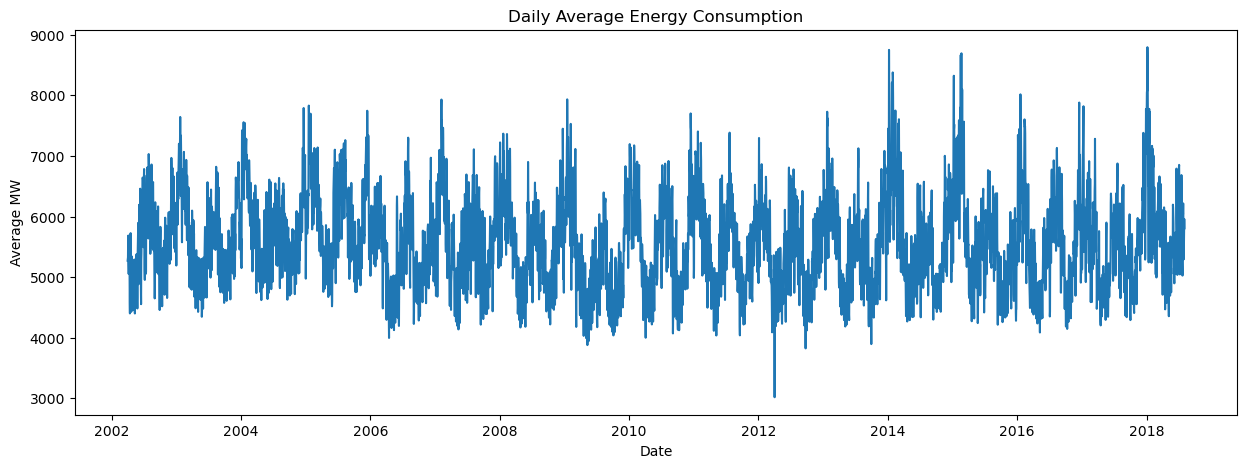

In [27]:
#Plot daily average
plt.figure(figsize=(15, 5))

plt.plot(daily_stats.index, daily_stats["mean"])

plt.title("Daily Average Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Average MW")

plt.show()

## STEP 14 — Monthly Analysis

In [28]:
monthly = df["PJMW_MW"].resample("ME").mean()

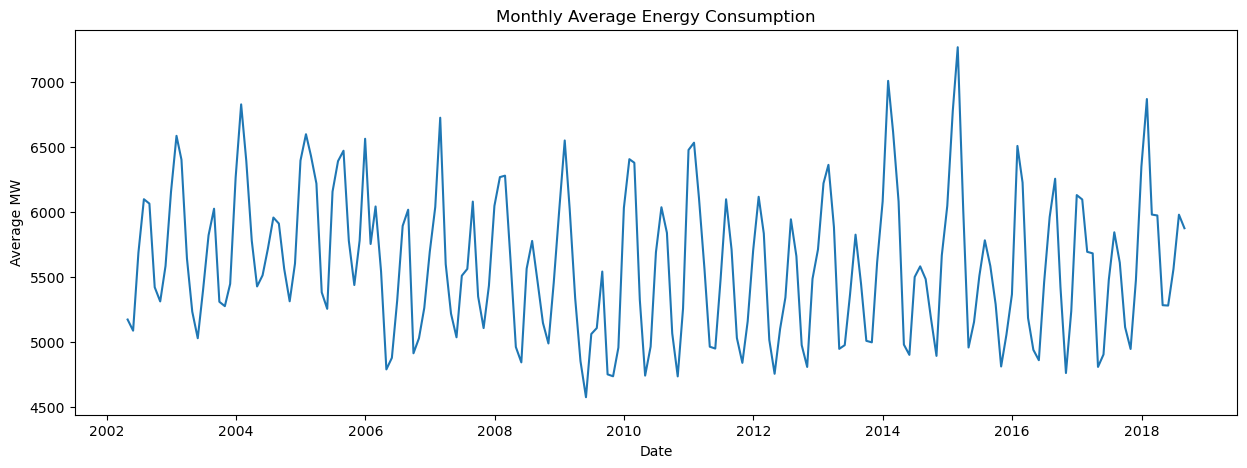

In [29]:
plt.figure(figsize=(15,5))

plt.plot(monthly.index, monthly)

plt.title("Monthly Average Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Average MW")

plt.show() 

## STEP 15 — Yearly Analysis

In [30]:
yearly = df["PJMW_MW"].resample("YE").mean()

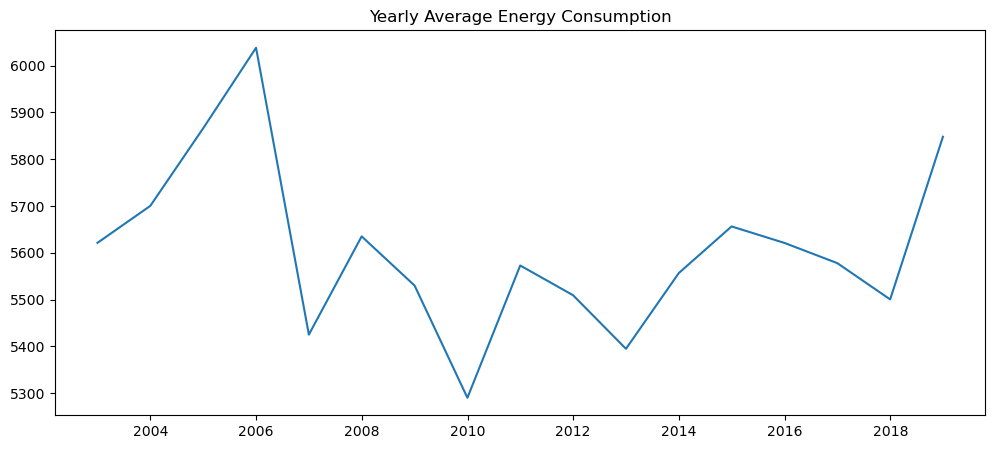

In [31]:
plt.figure(figsize=(12,5))

plt.plot(yearly.index, yearly)

plt.title("Yearly Average Energy Consumption")

plt.show()

## STEP 16 — Extract Date Features

In [32]:
df["year"] = df.index.year
df["month"] = df.index.month
df["day"] = df.index.day
df["hour"] = df.index.hour
df["dayofweek"] = df.index.dayofweek
df["dayofyear"] = df.index.dayofyear
df["weekofyear"] = df.index.isocalendar().week.astype(int)
df["quarter"] = df.index.quarter

## STEP 17 — Weekend Feature 

In [33]:
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

0 → Weekday
1 → Weekend

## STEP 18 — Season Feature 

In [34]:
#creating 
def get_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Spring"

    elif month in [6, 7, 8]:
        return "Summer"

    else:
        return "Autumn"

In [35]:
df["season"] = df["month"].apply(get_season)

In [36]:
df["season"].value_counts()

season
Summer    36841
Spring    36791
Autumn    34944
Winter    34656
Name: count, dtype: int64

## STEP 19 — Hourly Consumption Pattern 

In [37]:
hourly_pattern = df.groupby("hour")["PJMW_MW"].mean()

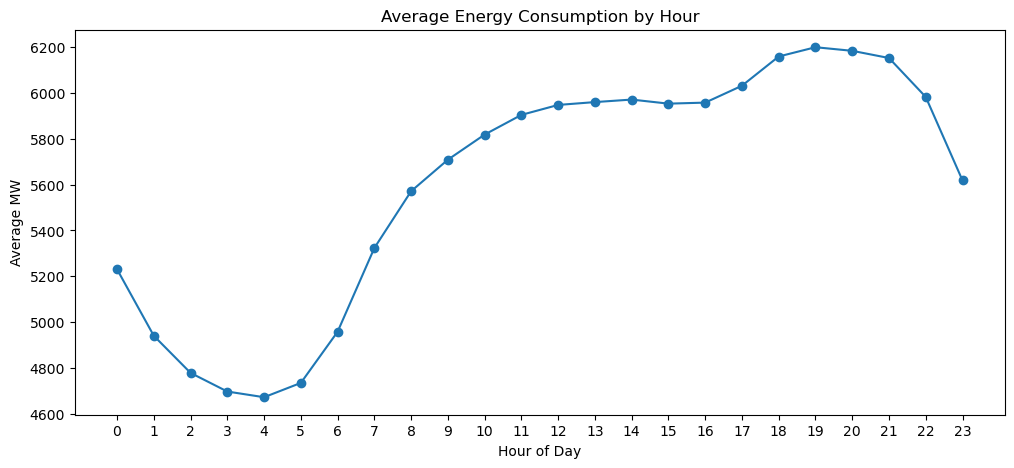

In [38]:
plt.figure(figsize=(12,5))

plt.plot(hourly_pattern.index, hourly_pattern.values, marker="o")

plt.title("Average Energy Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average MW")

plt.xticks(range(24))

plt.show()

## STEP 20 — Weekday vs Weekend 

In [39]:
weekday_pattern = df.groupby("is_weekend")["PJMW_MW"].mean()

print(weekday_pattern)

is_weekend
0    5754.354186
1    5221.507776
Name: PJMW_MW, dtype: float64


In [40]:
df.groupby("dayofweek")["PJMW_MW"].mean()

dayofweek
0    5700.518783
1    5801.076837
2    5802.370701
3    5780.841051
4    5686.885129
5    5293.999413
6    5149.016138
Name: PJMW_MW, dtype: float64

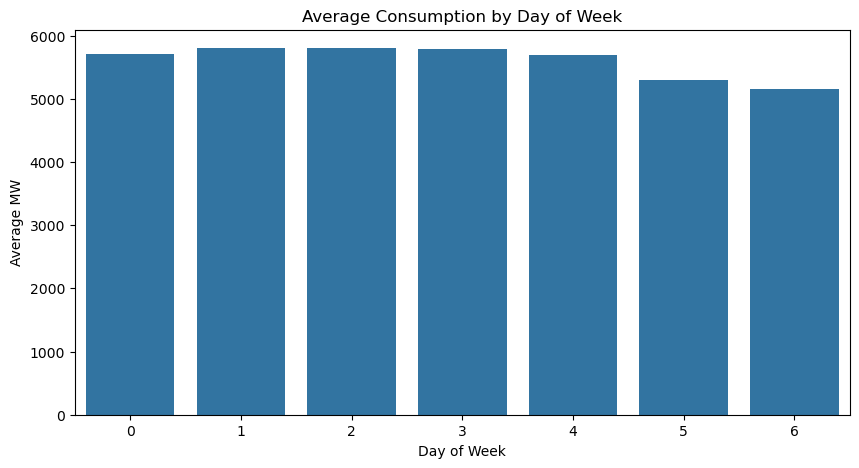

In [41]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=df.groupby("dayofweek")["PJMW_MW"].mean().index,
    y=df.groupby("dayofweek")["PJMW_MW"].mean().values
)

plt.title("Average Consumption by Day of Week")

plt.xlabel("Day of Week")
plt.ylabel("Average MW")

plt.show()

## STEP 21 — Monthly Pattern 

In [42]:
monthly_pattern = df.groupby("month")["PJMW_MW"].mean()

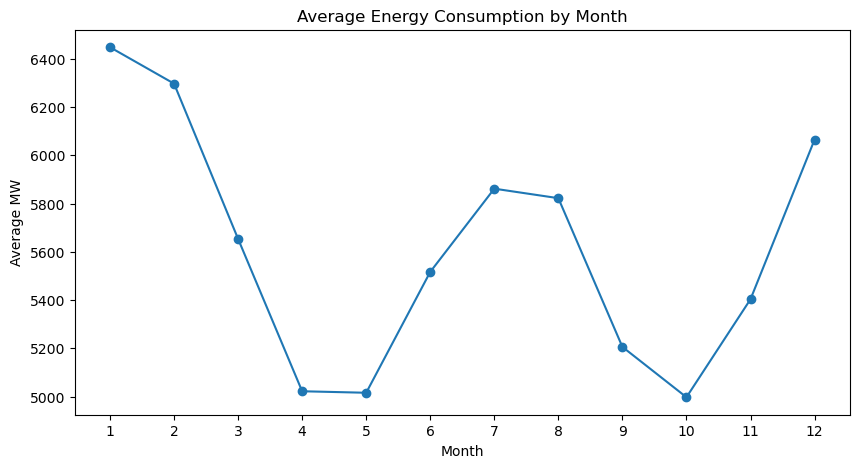

In [43]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_pattern.index,
    monthly_pattern.values,
    marker="o"
)

plt.title("Average Energy Consumption by Month")

plt.xlabel("Month")
plt.ylabel("Average MW")

plt.xticks(range(1,13))

plt.show()

This helps demonstrate the requirement:

Summer trends are very different from winter trends.

## STEP 22 — Summer vs Winter

In [44]:
season_pattern = df.groupby("season")["PJMW_MW"].mean()

print(season_pattern)

season
Autumn    5199.948646
Spring    5224.188212
Summer    5734.206129
Winter    6268.824157
Name: PJMW_MW, dtype: float64


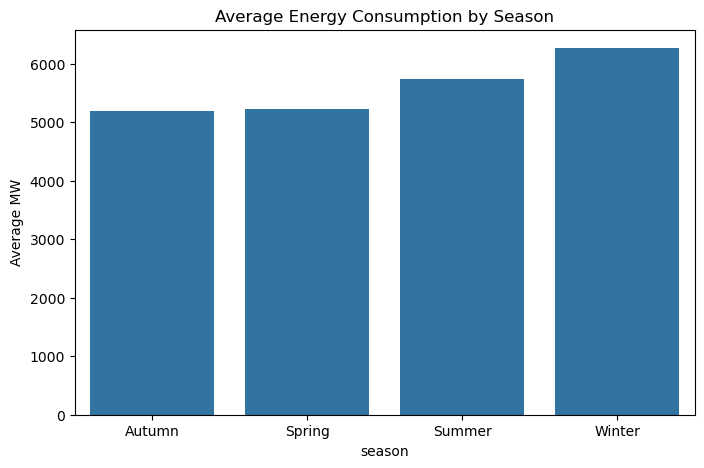

In [45]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=season_pattern.index,
    y=season_pattern.values
)

plt.title("Average Energy Consumption by Season")

plt.ylabel("Average MW")

plt.show()

## STEP 23 — Hour × Season Analysis 

In [46]:
hour_season = df.pivot_table(
    values="PJMW_MW",
    index="hour",
    columns="season",
    aggfunc="mean"
)

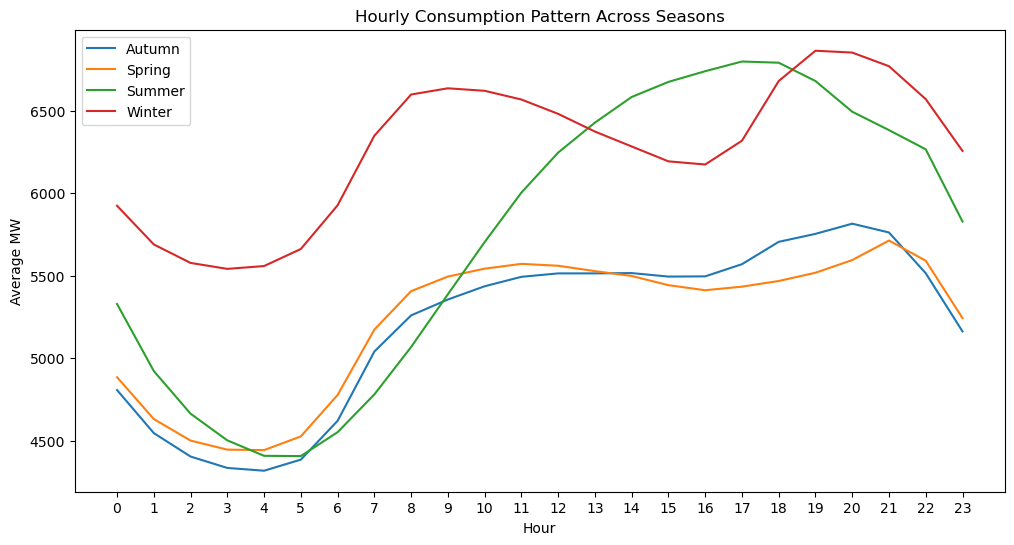

In [47]:
plt.figure(figsize=(12,6))

for season in hour_season.columns:
    plt.plot(
        hour_season.index,
        hour_season[season],
        label=season
    )

plt.title("Hourly Consumption Pattern Across Seasons")
plt.xlabel("Hour")
plt.ylabel("Average MW")
plt.legend()

plt.xticks(range(24))

plt.show()

This directly answers:

How do daily trends change depending on the time of year?

## STEP 24 — Heatmap of Hour vs Day of Week

In [48]:
heatmap_data = df.pivot_table(
    values="PJMW_MW",
    index="dayofweek",
    columns="hour",
    aggfunc="mean"
)

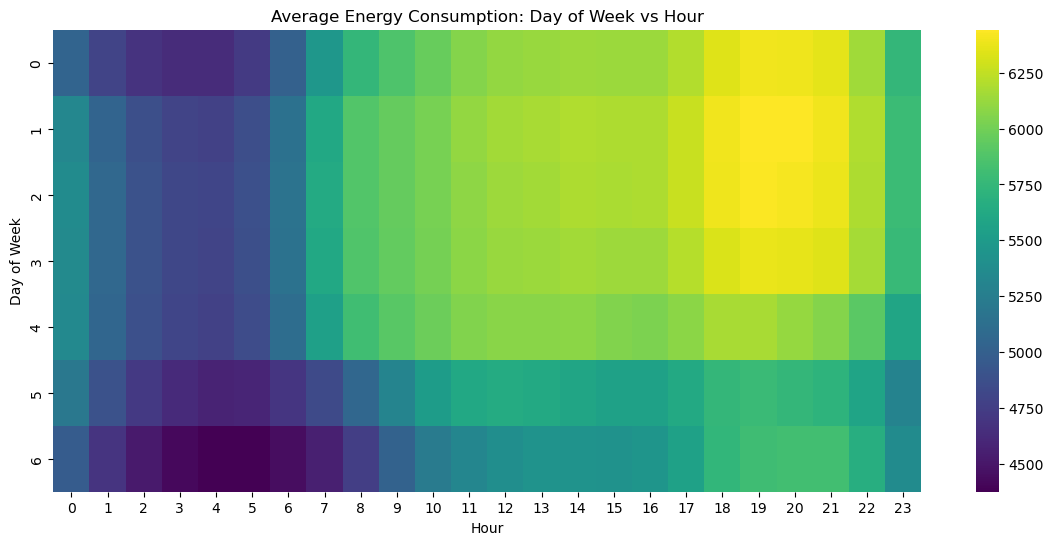

In [49]:
plt.figure(figsize=(14,6))

sns.heatmap(
    heatmap_data,
    cmap="viridis"
)

plt.title("Average Energy Consumption: Day of Week vs Hour")

plt.xlabel("Hour")
plt.ylabel("Day of Week")

plt.show()

## STEP 25 — Holiday Analysis 

In [50]:
pip install holidays

Note: you may need to restart the kernel to use updated packages.


In [51]:
import holidays

In [52]:
#Because this is U.S. PJM data
us_holidays = holidays.US()

In [53]:
df["is_holiday"] = df.index.normalize().isin(
    pd.to_datetime(list(us_holidays)).normalize()
).astype(int)

In [54]:
df.groupby("is_holiday")["PJMW_MW"].mean()

is_holiday
0    5602.214393
Name: PJMW_MW, dtype: float64

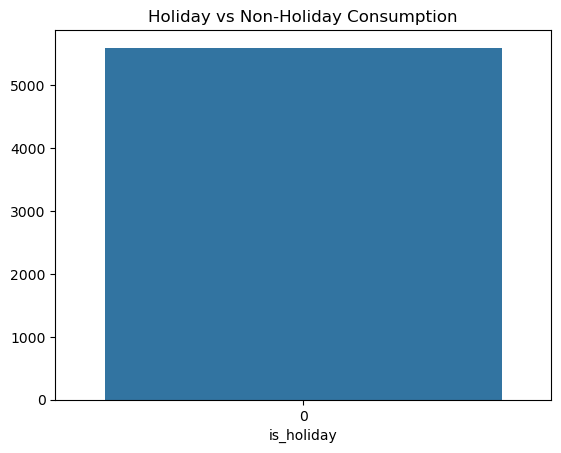

In [55]:
sns.barplot(
    x=df.groupby("is_holiday")["PJMW_MW"].mean().index,
    y=df.groupby("is_holiday")["PJMW_MW"].mean().values
)

plt.title("Holiday vs Non-Holiday Consumption")
plt.show()

## STEP 26 — Correlation Analysis

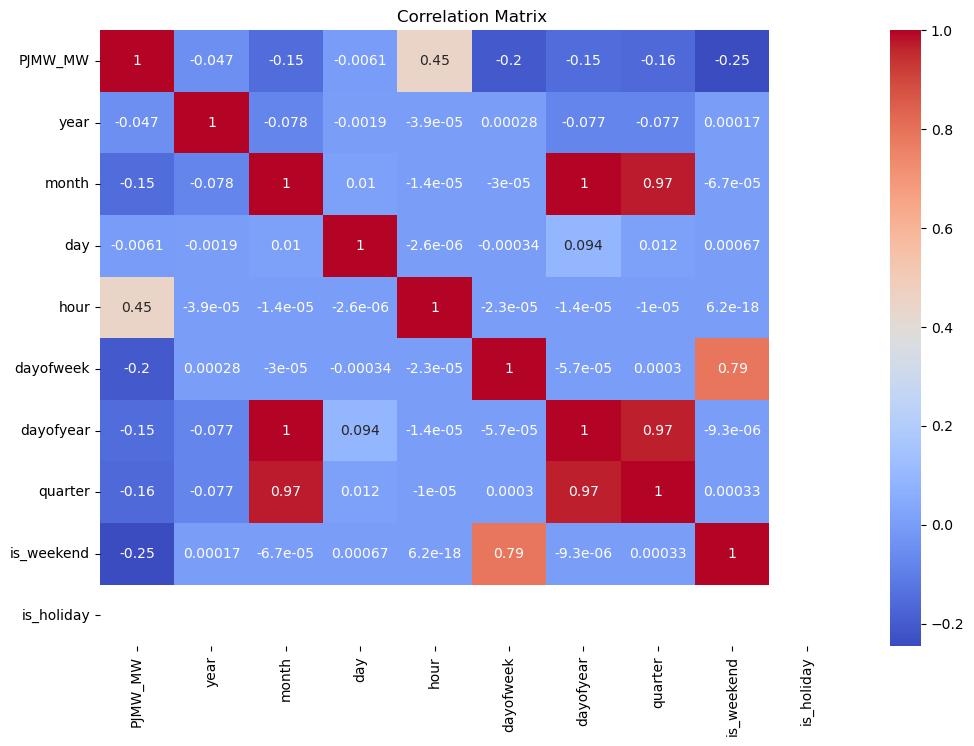

In [56]:
numeric_cols = [
    "PJMW_MW",
    "year",
    "month",
    "day",
    "hour",
    "dayofweek",
    "dayofyear",
    "quarter",
    "is_weekend",
    "is_holiday"
]

plt.figure(figsize=(12,8))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

## STEP 27 — Time-Series Features for ML 

Now we move from EDA to actual forecasting.

The most important features are lag features.

### *Previous hour*

In [57]:
df["lag_1"] = df["PJMW_MW"].shift(1)

### *Previous 24 hours*

In [58]:
df["lag_24"] = df["PJMW_MW"].shift(24)

### *Previous 48 hours*

In [59]:
df["lag_48"] = df["PJMW_MW"].shift(48)

### *Previous week*

In [60]:
df["lag_168"] = df["PJMW_MW"].shift(168)

* 24 hours × 7 days = 168 hours
* This is extremely useful for hourly electricity forecasting.

## STEP 28 — Rolling Features

In [61]:
df["rolling_mean_24"] = (
    df["PJMW_MW"]
    .shift(1)
    .rolling(24)
    .mean()
)

In [62]:
#Weekly rolling average:
df["rolling_mean_168"] = (
    df["PJMW_MW"]
    .shift(1)
    .rolling(168)
    .mean()
)

In [63]:
#Rolling standard deviation:
df["rolling_std_24"] = (
    df["PJMW_MW"]
    .shift(1)
    .rolling(24)
    .std()
)

## STEP 29 — Cyclic Features

Hour 23 and hour 0 are actually close to each other.

Instead of treating them as completely different numbers, encode them cyclically.

In [64]:
df["hour_sin"] = np.sin(
    2 * np.pi * df["hour"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour"] / 24
)

In [65]:
#For day of year:
df["dayofyear_sin"] = np.sin(
    2 * np.pi * df["dayofyear"] / 365
)

df["dayofyear_cos"] = np.cos(
    2 * np.pi * df["dayofyear"] / 365
)

## STEP 30 — Remove Rows Created by Lagging 

In [66]:
#After creating lag/rolling features:
df = df.dropna() 

In [67]:
df.isnull().sum()

PJMW_MW             0
year                0
month               0
day                 0
hour                0
dayofweek           0
dayofyear           0
weekofyear          0
quarter             0
is_weekend          0
season              0
is_holiday          0
lag_1               0
lag_24              0
lag_48              0
lag_168             0
rolling_mean_24     0
rolling_mean_168    0
rolling_std_24      0
hour_sin            0
hour_cos            0
dayofyear_sin       0
dayofyear_cos       0
dtype: int64

## STEP 31 — Train/Test Split

The requirement explicitly says:

Split the last year into a test set.

Do not randomly split the data.

In [68]:
test_start = df.index.max() - pd.Timedelta(days=365)

train = df[df.index < test_start].copy()
test = df[df.index >= test_start].copy()

In [69]:
print(train.index.min())
print(train.index.max())

print(test.index.min())
print(test.index.max())

2002-04-08 01:00:00
2017-08-02 23:00:00
2017-08-03 00:00:00
2018-08-03 00:00:00


## STEP 32 — Select Features 

In [70]:
features = [
    "year",
    "month",
    "day",
    "hour",
    "dayofweek",
    "dayofyear",
    "quarter",
    "is_weekend",
    "is_holiday",
    "lag_1",
    "lag_24",
    "lag_48",
    "lag_168",
    "rolling_mean_24",
    "rolling_mean_168",
    "rolling_std_24",
    "hour_sin",
    "hour_cos",
    "dayofyear_sin",
    "dayofyear_cos"
]

In [71]:
target = "PJMW_MW"

In [72]:
X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

## STEP 33 — Create Daily Dataset 

In [73]:
# Make sure index is datetime
df.index = pd.to_datetime(df.index)

# Daily average electricity demand
daily = df["PJMW_MW"].resample("D").mean().to_frame()
daily = daily.iloc[:-1]
print(daily.head())
print(daily.shape)
print(daily.index.min())
print(daily.index.max())

                PJMW_MW
Datetime               
2002-04-08  5305.000000
2002-04-09  5136.083333
2002-04-10  5171.666667
2002-04-11  5207.875000
2002-04-12  5090.416667
(5961, 1)
2002-04-08 00:00:00
2018-08-02 00:00:00


## STEP 34 — Last-Year Daily Train/Test Split 

In [74]:
test_start = daily.index.max() - pd.Timedelta(days=365)

train_daily = daily[daily.index < test_start].copy()
test_daily = daily[daily.index >= test_start].copy()

print("TRAIN")
print(train_daily.index.min())
print(train_daily.index.max())
print(train_daily.shape)

print("\nTEST")
print(test_daily.index.min())
print(test_daily.index.max())
print(test_daily.shape)

TRAIN
2002-04-08 00:00:00
2017-08-01 00:00:00
(5595, 1)

TEST
2017-08-02 00:00:00
2018-08-02 00:00:00
(366, 1)


## STEP 35 — Visualize Train/Test Split 

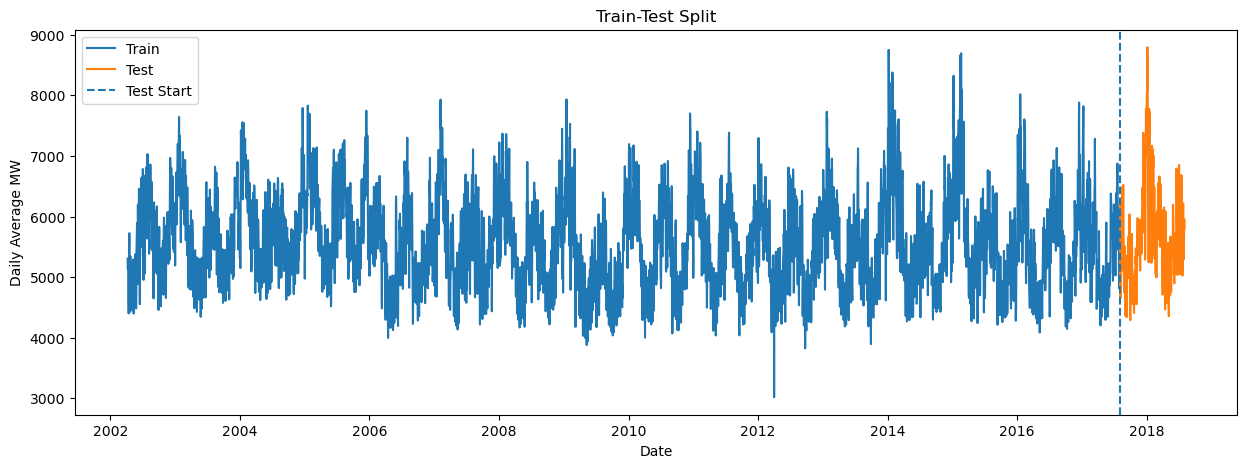

In [75]:
plt.figure(figsize=(15, 5))

plt.plot(train_daily.index,
         train_daily["PJMW_MW"],
         label="Train")

plt.plot(test_daily.index,
         test_daily["PJMW_MW"],
         label="Test")

plt.axvline(
    test_start,
    linestyle="--",
    label="Test Start"
)

plt.title("Train-Test Split")
plt.xlabel("Date")
plt.ylabel("Daily Average MW")
plt.legend()
plt.show()

It visually proves that I used a chronological split, not a random split.

## ADF Stationarity Test

## Augmented Dickey-Fuller (ADF) Test

Before applying ARIMA and SARIMA, we check whether the training time series is stationary.

ADF Test:

H0: The time series is non-stationary.
H1: The time series is stationary.

If p-value < 0.05:
    Reject H0 → Series is stationary.

If p-value >= 0.05:
    Fail to reject H0 → Series is non-stationary.

In [76]:
from statsmodels.tsa.stattools import adfuller

train_series = train_daily["PJMW_MW"]

adf_result = adfuller(train_series.dropna())

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

ADF Statistic: -7.14911033073346
p-value: 3.1752167160188e-10

Critical Values:
1%: -3.4315264648607156
5%: -2.8620598817961898
10%: -2.567046731725405


## First Differencing

Now we check whether one difference makes the series stationary.

In [77]:
train_diff = train_series.diff().dropna()

adf_diff_result = adfuller(train_diff)

print("ADF Test After First Differencing")
print("ADF Statistic:", adf_diff_result[0])
print("p-value:", adf_diff_result[1])

print("\nCritical Values:")
for key, value in adf_diff_result[4].items():
    print(f"{key}: {value}")

ADF Test After First Differencing
ADF Statistic: -16.415000924987318
p-value: 2.56225475654298e-29

Critical Values:
1%: -3.4315264648607156
5%: -2.8620598817961898
10%: -2.567046731725405


## Decide d

In [78]:
original_pvalue = adf_result[1]
diff_pvalue = adf_diff_result[1]

if original_pvalue < 0.05:
    d = 0
    print("Original series is stationary.")
    print("Use d =", d)

elif diff_pvalue < 0.05:
    d = 1
    print("Original series is non-stationary.")
    print("First differencing makes it stationary.")
    print("Use d =", d)

else:
    d = 2
    print("Series is still non-stationary after first differencing.")
    print("Consider second differencing.")
    print("Use d =", d)

Original series is stationary.
Use d = 0


In [79]:
seasonal_diff = train_series.diff(7).dropna()

seasonal_adf_result = adfuller(seasonal_diff)

print("ADF Test After Seasonal Differencing (lag=7)")
print("ADF Statistic:", seasonal_adf_result[0])
print("p-value:", seasonal_adf_result[1])

print("\nCritical Values:")
for key, value in seasonal_adf_result[4].items():
    print(f"{key}: {value}")

ADF Test After Seasonal Differencing (lag=7)
ADF Statistic: -13.648865297379773
p-value: 1.600062384938603e-25

Critical Values:
1%: -3.431527948307764
5%: -2.862060537204083
10%: -2.567047080619664


## MODEL 1 — ARIMA

## STEP 36 — Import ARIMA 

In [80]:
from statsmodels.tsa.arima.model import ARIMA

## STEP 37 — Train ARIMA

In [81]:
train_series = train_daily["PJMW_MW"]

arima_model = ARIMA(
    train_series,
    order=(1, 0, 1)
)

arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                PJMW_MW   No. Observations:                 5595
Model:                 ARIMA(1, 0, 1)   Log Likelihood              -40956.232
Date:                Mon, 12 Oct 2026   AIC                          81920.465
Time:                        13:27:43   BIC                          81946.983
Sample:                    04-08-2002   HQIC                         81929.706
                         - 08-01-2017                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       5595.9341     28.636    195.414      0.000    5539.808    5652.060
ar.L1          0.7426      0.009     79.209      0.000       0.724       0.761
ma.L1          0.4274      0.013     32.330      0.0

## STEP 38 — ARIMA Prediction

In [82]:
arima_pred = arima_fit.forecast(
    steps=len(test_daily)
)

arima_pred.index = test_daily.index

print(arima_pred.head())

Datetime
2017-08-02    5919.586132
2017-08-03    5836.289692
2017-08-04    5774.430775
2017-08-05    5728.492130
2017-08-06    5694.376448
Freq: D, Name: predicted_mean, dtype: float64


## STEP 39 — Evaluate ARIMA 

In [83]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

def calculate_metrics(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return mae, rmse, r2, mape


arima_mae, arima_rmse, arima_r2, arima_mape = calculate_metrics(
    test_daily["PJMW_MW"],
    arima_pred
)

print("ARIMA")
print("MAE :", arima_mae)
print("RMSE:", arima_rmse)
print("R2  :", arima_r2)
print("MAPE:", arima_mape)

ARIMA
MAE : 578.7998336060645
RMSE: 772.9551076783212
R2  : -0.018304148465073444
MAPE: 9.892724870427521


## STEP 40 — ARIMA Actual vs Predicted 

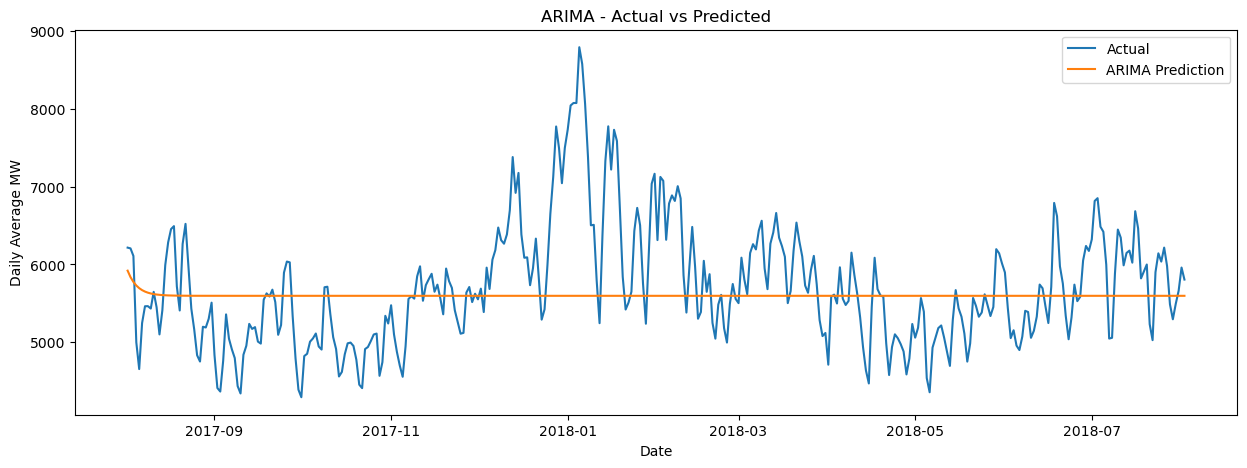

In [84]:
plt.figure(figsize=(15, 5))

plt.plot(
    test_daily.index,
    test_daily["PJMW_MW"],
    label="Actual"
)

plt.plot(
    test_daily.index,
    arima_pred,
    label="ARIMA Prediction"
)

plt.title("ARIMA - Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Daily Average MW")
plt.legend()
plt.show()

## MODEL 2 — SARIMA 

SARIMA is useful because electricity demand has seasonality.

For daily data, we can use a weekly seasonal period: 

## STEP 41 — Import SARIMA 

In [85]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

## STEP 42 — Train SARIMA 

We use:

SARIMA(1,0,1)(1,0,1,7)

In [86]:
sarima_model = SARIMAX(
    train_series,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(
    disp=False
)

print(sarima_fit.summary())

                                     SARIMAX Results                                     
Dep. Variable:                           PJMW_MW   No. Observations:                 5595
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood              -39920.449
Date:                           Mon, 12 Oct 2026   AIC                          79850.897
Time:                                   13:27:56   BIC                          79884.037
Sample:                               04-08-2002   HQIC                         79862.447
                                    - 08-01-2017                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8535      0.013     63.716      0.000       0.827       0.880
ma.L1          0.3185      0.021     15.493

## STEP 43 — SARIMA Prediction 

In [87]:
sarima_pred = sarima_fit.forecast(
    steps=len(test_daily)
)

sarima_pred.index = test_daily.index

## STEP 44 — Evaluate SARIMA 

In [88]:
sarima_mae, sarima_rmse, sarima_r2, sarima_mape = calculate_metrics(
    test_daily["PJMW_MW"],
    sarima_pred
)

print("SARIMA")
print("MAE :", sarima_mae)
print("RMSE:", sarima_rmse)
print("R2  :", sarima_r2)
print("MAPE:", sarima_mape)

SARIMA
MAE : 563.5870741965147
RMSE: 776.1042330660722
R2  : -0.026618473113976027
MAPE: 9.348673528606806


## STEP 45 — SARIMA Plot 

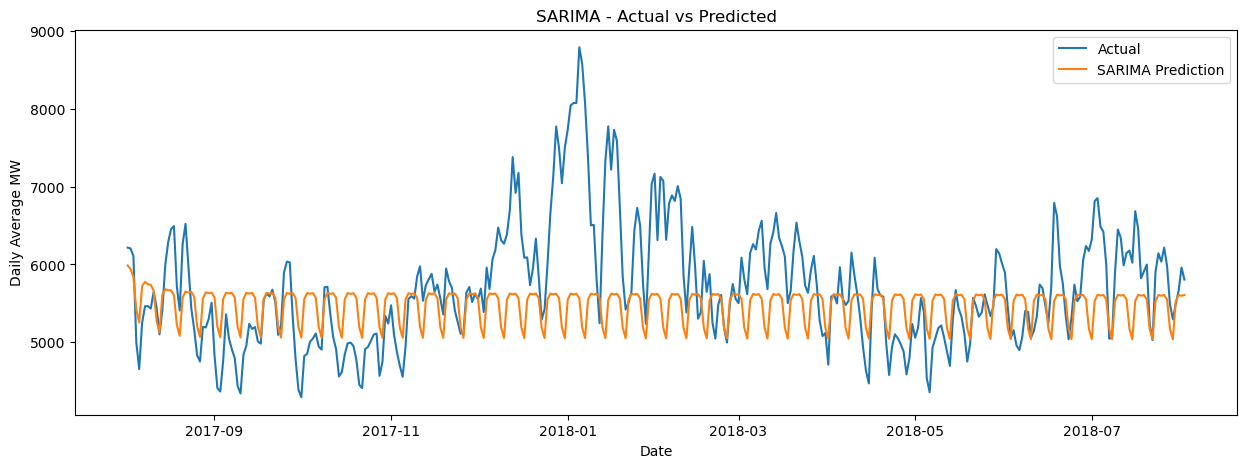

In [89]:
plt.figure(figsize=(15, 5))

plt.plot(
    test_daily.index,
    test_daily["PJMW_MW"],
    label="Actual"
)

plt.plot(
    test_daily.index,
    sarima_pred,
    label="SARIMA Prediction"
)

plt.title("SARIMA - Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Daily Average MW")
plt.legend()

plt.show()

## MODEL 3 — XGBOOST

Now we move from classical time-series models to machine learning.

## STEP 46 — Create Daily ML Features

In [90]:
ml_daily = daily.copy()

# Calendar features
ml_daily["year"] = ml_daily.index.year
ml_daily["month"] = ml_daily.index.month
ml_daily["day"] = ml_daily.index.day
ml_daily["dayofweek"] = ml_daily.index.dayofweek
ml_daily["dayofyear"] = ml_daily.index.dayofyear
ml_daily["quarter"] = ml_daily.index.quarter

ml_daily["is_weekend"] = (
    ml_daily["dayofweek"] >= 5
).astype(int)

# Lag features
ml_daily["lag_1"] = ml_daily["PJMW_MW"].shift(1)
ml_daily["lag_7"] = ml_daily["PJMW_MW"].shift(7)
ml_daily["lag_14"] = ml_daily["PJMW_MW"].shift(14)
ml_daily["lag_28"] = ml_daily["PJMW_MW"].shift(28)

# Rolling features
ml_daily["rolling_mean_7"] = (
    ml_daily["PJMW_MW"]
    .shift(1)
    .rolling(7)
    .mean()
)

ml_daily["rolling_mean_30"] = (
    ml_daily["PJMW_MW"]
    .shift(1)
    .rolling(30)
    .mean()
)

ml_daily["rolling_std_7"] = (
    ml_daily["PJMW_MW"]
    .shift(1)
    .rolling(7)
    .std()
)

# Cyclic features
ml_daily["dow_sin"] = np.sin(
    2 * np.pi * ml_daily["dayofweek"] / 7
)

ml_daily["dow_cos"] = np.cos(
    2 * np.pi * ml_daily["dayofweek"] / 7
)

ml_daily["doy_sin"] = np.sin(
    2 * np.pi * ml_daily["dayofyear"] / 365
)

ml_daily["doy_cos"] = np.cos(
    2 * np.pi * ml_daily["dayofyear"] / 365
)

## STEP 47 — Remove Missing Values

In [91]:
#The first few rows have missing lag/rolling values.
ml_daily = ml_daily.dropna()

print(ml_daily.shape)

(5931, 19)


## STEP 48 — Split ML Data Chronologically 

In [92]:
train_ml = ml_daily[
    ml_daily.index < test_start
].copy()

test_ml = ml_daily[
    ml_daily.index >= test_start
].copy()

## STEP 49 — Select ML Features 

In [93]:
features_ml = [
    "year",
    "month",
    "day",
    "dayofweek",
    "dayofyear",
    "quarter",
    "is_weekend",

    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",

    "rolling_mean_7",
    "rolling_mean_30",
    "rolling_std_7",

    "dow_sin",
    "dow_cos",
    "doy_sin",
    "doy_cos"
]

target = "PJMW_MW"

## STEP 50 — Create X and y 

In [94]:
X_train_ml = train_ml[features_ml]
y_train_ml = train_ml[target]

X_test_ml = test_ml[features_ml]
y_test_ml = test_ml[target]

print("X_train:", X_train_ml.shape)
print("X_test :", X_test_ml.shape)

X_train: (5565, 18)
X_test : (366, 18)


## STEP 51 — Train XGBoost 

In [95]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=600,
    max_depth=7,
    learning_rate=0.04,
    subsample=0.85,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    n_jobs=4,
    random_state=42
)

xgb_model.fit(
    X_train_ml,
    y_train_ml
)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.9
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


## STEP 52 — XGBoost Prediction 

In [96]:
xgb_pred = xgb_model.predict(
    X_test_ml
)

xgb_pred = pd.Series(
    xgb_pred,
    index=test_ml.index
)

## STEP 53 — Evaluate XGBoost 

In [97]:
xgb_mae, xgb_rmse, xgb_r2, xgb_mape = calculate_metrics(
    y_test_ml,
    xgb_pred
)

print("XGBOOST")
print("MAE :", xgb_mae)
print("RMSE:", xgb_rmse)
print("R2  :", xgb_r2)
print("MAPE:", xgb_mape)

XGBOOST
MAE : 257.5157530737705
RMSE: 349.9700494552452
R2  : 0.7912479600600697
MAPE: 4.330549455357546


## MODEL 4 — RANDOM FOREST 

## STEP 54 — Train Random Forest 

In [98]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=250,
    max_depth=18,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42
)

rf_model.fit(
    X_train_ml,
    y_train_ml
)

,n_estimators,250
,criterion,'squared_error'
,max_depth,18
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## STEP 55 — Random Forest Prediction 

In [99]:
rf_pred = rf_model.predict(
    X_test_ml
)

rf_pred = pd.Series(
    rf_pred,
    index=test_ml.index
)

## STEP 56 — Evaluate Random Forest 

In [100]:
rf_mae, rf_rmse, rf_r2, rf_mape = calculate_metrics(
    y_test_ml,
    rf_pred
)

print("RANDOM FOREST")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2  :", rf_r2)
print("MAPE:", rf_mape)

RANDOM FOREST
MAE : 251.68040193777557
RMSE: 333.43648899433435
R2  : 0.8105061066341711
MAPE: 4.285954796141689


## STEP 57 — Random Forest Actual vs Predicted 

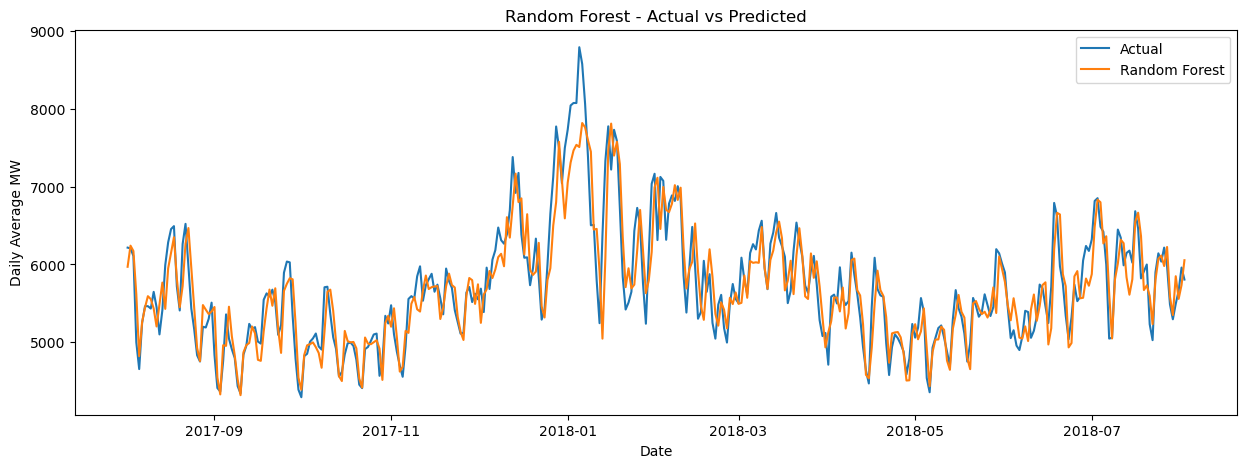

In [101]:
plt.figure(figsize=(15, 5))

plt.plot(
    y_test_ml.index,
    y_test_ml,
    label="Actual"
)

plt.plot(
    rf_pred.index,
    rf_pred,
    label="Random Forest"
)

plt.title("Random Forest - Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Daily Average MW")
plt.legend()

plt.show()

## MODEL 5 — LSTM 
Now we use a recurrent neural network.

## STEP 58 — Prepare LSTM Data

We will use the previous 30 days to predict the next day.

In [102]:
from sklearn.preprocessing import StandardScaler

lookback = 30

train_values = train_daily["PJMW_MW"].values.reshape(-1, 1)
test_values = test_daily["PJMW_MW"].values.reshape(-1, 1)

scaler = StandardScaler()

train_scaled = scaler.fit_transform(
    train_values
)

test_scaled = scaler.transform(
    test_values
)

## STEP 59 — Create Sequences 

In [103]:
def create_sequences(data, lookback):

    X = []
    y = []

    for i in range(lookback, len(data)):

        X.append(
            data[i-lookback:i]
        )

        y.append(
            data[i]
        )

    return np.array(X), np.array(y)

In [104]:
# for training 
X_lstm_train, y_lstm_train = create_sequences(
    train_scaled,
    lookback
)

In [105]:
#For testing, we need the last 30 training days before the test period.
combined = np.concatenate([
    train_scaled[-lookback:],
    test_scaled
])

X_lstm_test, y_lstm_test = create_sequences(
    combined,
    lookback
) 

## STEP 60 — Import PyTorch 

In [106]:
!pip install torch torchvision torchaudio


In [107]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader

In [108]:
#convert data 
X_lstm_train = torch.tensor(
    X_lstm_train,
    dtype=torch.float32
)

y_lstm_train = torch.tensor(
    y_lstm_train,
    dtype=torch.float32
)

X_lstm_test = torch.tensor(
    X_lstm_test,
    dtype=torch.float32
)

y_lstm_test = torch.tensor(
    y_lstm_test,
    dtype=torch.float32
)

## STEP 61 — LSTM Model 

In [109]:
class LSTMModel(nn.Module):

    def __init__(self):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=32,
            batch_first=True
        )

        self.fc = nn.Linear(
            32,
            1
        )

    def forward(self, x):

        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        return self.fc(last_output)

In [110]:
#create model 
lstm_model = LSTMModel()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

## STEP 62 — Train LSTM 

In [111]:
dataset = TensorDataset(
    X_lstm_train,
    y_lstm_train
)

loader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=False
)

epochs = 8

for epoch in range(epochs):

    lstm_model.train()

    total_loss = 0

    for X_batch, y_batch in loader:

        optimizer.zero_grad()

        predictions = lstm_model(
            X_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"Loss: {total_loss/len(loader):.4f}"
    )

Epoch 1/8 Loss: 0.8362
Epoch 2/8 Loss: 0.5031
Epoch 3/8 Loss: 0.4269
Epoch 4/8 Loss: 0.4009
Epoch 5/8 Loss: 0.3758
Epoch 6/8 Loss: 0.3479
Epoch 7/8 Loss: 0.3155
Epoch 8/8 Loss: 0.2816


## STEP 63 — LSTM Prediction 

In [112]:
lstm_model.eval()

with torch.no_grad():

    lstm_scaled_pred = lstm_model(
        X_lstm_test
    ).numpy()

In [113]:
lstm_pred_values = scaler.inverse_transform(
    lstm_scaled_pred
).flatten()

lstm_pred = pd.Series(
    lstm_pred_values,
    index=test_daily.index
)

## STEP 64 — Evaluate LSTM 

In [114]:
lstm_mae, lstm_rmse, lstm_r2, lstm_mape = calculate_metrics(
    test_daily["PJMW_MW"],
    lstm_pred
)

print("LSTM")
print("MAE :", lstm_mae)
print("RMSE:", lstm_rmse)
print("R2  :", lstm_r2)
print("MAPE:", lstm_mape)

LSTM
MAE : 309.6366218052709
RMSE: 395.25636583770864
R2  : 0.733727254149497
MAPE: 5.383363411830398


## MODEL 6 — GRU 

## STEP 65 — GRU Model 

In [115]:
class GRUModel(nn.Module):

    def __init__(self):

        super().__init__()

        self.gru = nn.GRU(
            input_size=1,
            hidden_size=32,
            batch_first=True
        )

        self.fc = nn.Linear(
            32,
            1
        )

    def forward(self, x):

        output, _ = self.gru(x)

        last_output = output[:, -1, :]

        return self.fc(last_output)

## STEP 66 — Train GRU 

In [116]:
gru_model = GRUModel()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    gru_model.parameters(),
    lr=0.001
)

In [117]:
for epoch in range(epochs):

    gru_model.train()

    total_loss = 0

    for X_batch, y_batch in loader:

        optimizer.zero_grad()

        predictions = gru_model(
            X_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"Loss: {total_loss/len(loader):.4f}"
    )

Epoch 1/8 Loss: 0.8692
Epoch 2/8 Loss: 0.4875
Epoch 3/8 Loss: 0.4001
Epoch 4/8 Loss: 0.3694
Epoch 5/8 Loss: 0.3351
Epoch 6/8 Loss: 0.2964
Epoch 7/8 Loss: 0.2684
Epoch 8/8 Loss: 0.2487


## STEP 67 — GRU Prediction 

In [118]:
gru_model.eval()

with torch.no_grad():

    gru_scaled_pred = gru_model(
        X_lstm_test
    ).numpy()

In [119]:
# convert back 
gru_pred_values = scaler.inverse_transform(
    gru_scaled_pred
).flatten()

gru_pred = pd.Series(
    gru_pred_values,
    index=test_daily.index
)

## STEP 68 — Evaluate GRU 

In [120]:
gru_mae, gru_rmse, gru_r2, gru_mape = calculate_metrics(
    test_daily["PJMW_MW"],
    gru_pred
)

print("GRU")
print("MAE :", gru_mae)
print("RMSE:", gru_rmse)
print("R2  :", gru_r2)
print("MAPE:", gru_mape)

GRU
MAE : 292.12956351747493
RMSE: 372.79336558876156
R2  : 0.7631325852529316
MAPE: 5.092459181884174


## STEP 69 — FINAL MODEL COMPARISON 

*Now combine all six models.*

In [121]:
results = pd.DataFrame({

    "Model": [
        "ARIMA",
        "SARIMA",
        "XGBoost",
        "Random Forest",
        "LSTM",
        "GRU"
    ],

    "MAE": [
        arima_mae,
        sarima_mae,
        xgb_mae,
        rf_mae,
        lstm_mae,
        gru_mae
    ],

    "RMSE": [
        arima_rmse,
        sarima_rmse,
        xgb_rmse,
        rf_rmse,
        lstm_rmse,
        gru_rmse
    ],

    "R2": [
        arima_r2,
        sarima_r2,
        xgb_r2,
        rf_r2,
        lstm_r2,
        gru_r2
    ],

    "MAPE": [
        arima_mape,
        sarima_mape,
        xgb_mape,
        rf_mape,
        lstm_mape,
        gru_mape
    ]
})

print(results)

           Model         MAE        RMSE        R2      MAPE
0          ARIMA  578.799834  772.955108 -0.018304  9.892725
1         SARIMA  563.587074  776.104233 -0.026618  9.348674
2        XGBoost  257.515753  349.970049  0.791248  4.330549
3  Random Forest  251.680402  333.436489  0.810506  4.285955
4           LSTM  309.636622  395.256366  0.733727  5.383363
5            GRU  292.129564  372.793366  0.763133  5.092459


## STEP 70 — Format Results 

In [122]:
results.round(4)

,Model,MAE,RMSE,R2,MAPE
0,ARIMA,578.7998,772.9551,-0.0183,9.8927
1,SARIMA,563.5871,776.1042,-0.0266,9.3487
2,XGBoost,257.5158,349.9700,0.7912,4.3305
3,Random Forest,251.6804,333.4365,0.8105,4.2860
4,LSTM,309.6366,395.2564,0.7337,5.3834
5,GRU,292.1296,372.7934,0.7631,5.0925


*For this particular configuration and test period, Random Forest produced the lowest MAE and RMSE among the six models.
That is a measured result on this test set, not a general statement that Random Forest is always better than the other methods.*

## STEP 71 — Save Model Comparison 

In [123]:
results.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved.")

Model comparison saved.


## STEP 72 — Feature Importance

Since Random Forest is the model we will use for the final forecast: 

In [124]:
importance = pd.DataFrame({

    "Feature": features_ml,

    "Importance": rf_model.feature_importances_

})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance)

            Feature  Importance
7             lag_1    0.764422
3         dayofweek    0.040420
14          dow_sin    0.028485
15          dow_cos    0.021515
11   rolling_mean_7    0.020297
6        is_weekend    0.014882
13    rolling_std_7    0.013720
8             lag_7    0.013313
17          doy_cos    0.013113
9            lag_14    0.012182
10           lag_28    0.010781
4         dayofyear    0.009940
12  rolling_mean_30    0.009266
0              year    0.008974
16          doy_sin    0.008658
2               day    0.008587
1             month    0.001167
5           quarter    0.000277


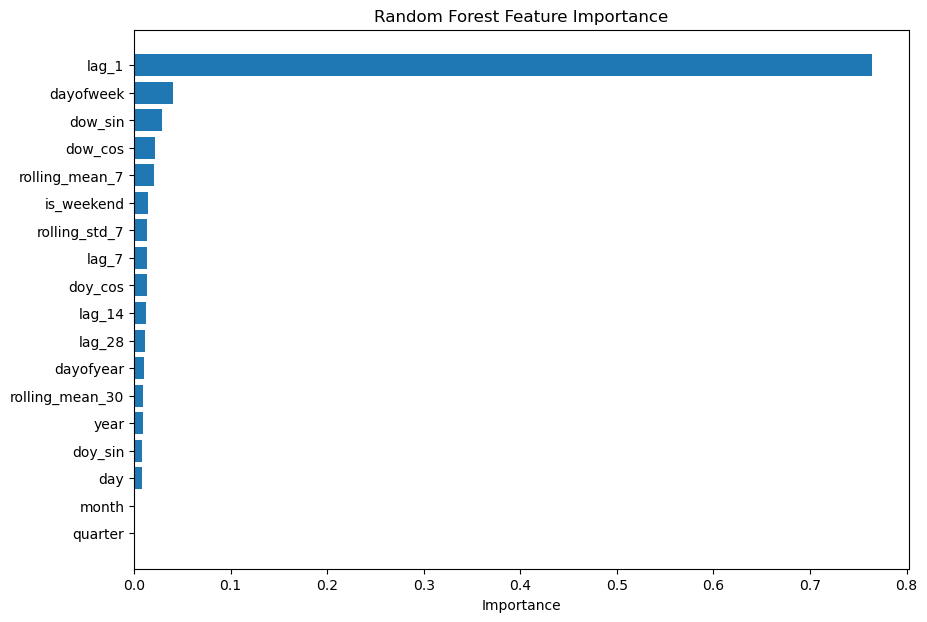

In [125]:
plt.figure(figsize=(10, 7))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel("Importance")

plt.show()

## STEP 73 — Actual vs All Model Predictions

Create one comparison plot.

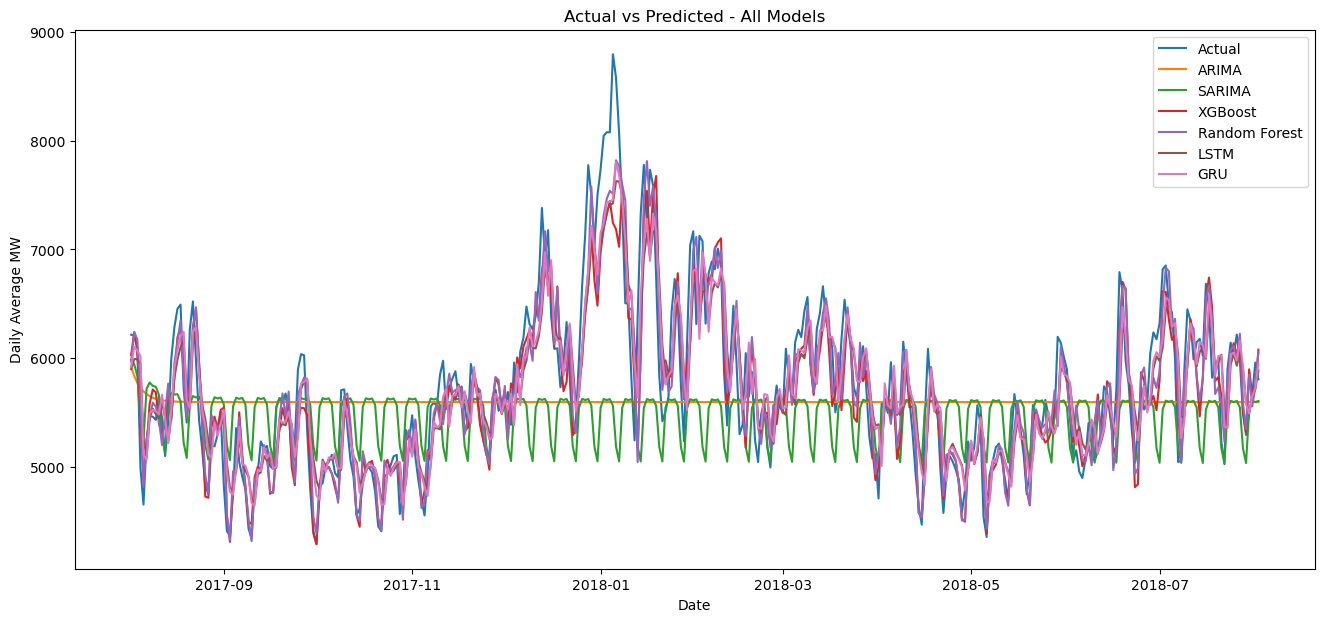

In [126]:
plt.figure(figsize=(16, 7))

plt.plot(
    test_daily.index,
    test_daily["PJMW_MW"],
    label="Actual"
)

plt.plot(
    test_daily.index,
    arima_pred,
    label="ARIMA"
)

plt.plot(
    test_daily.index,
    sarima_pred,
    label="SARIMA"
)

plt.plot(
    test_ml.index,
    xgb_pred,
    label="XGBoost"
)

plt.plot(
    test_ml.index,
    rf_pred,
    label="Random Forest"
)

plt.plot(
    test_daily.index,
    lstm_pred,
    label="LSTM"
)

plt.plot(
    test_daily.index,
    gru_pred,
    label="GRU"
)

plt.title(
    "Actual vs Predicted - All Models"
)

plt.xlabel("Date")
plt.ylabel("Daily Average MW")

plt.legend()

plt.show()

## STEP 74 — Residual Analysis

For the selected Random Forest model:

In [127]:
residuals = (
    y_test_ml - rf_pred
)

print(residuals.describe())

count     366.000000
mean       27.987062
std       332.714702
min      -946.321859
25%      -177.090563
50%        -3.422309
75%       227.989092
max      1330.479715
dtype: float64


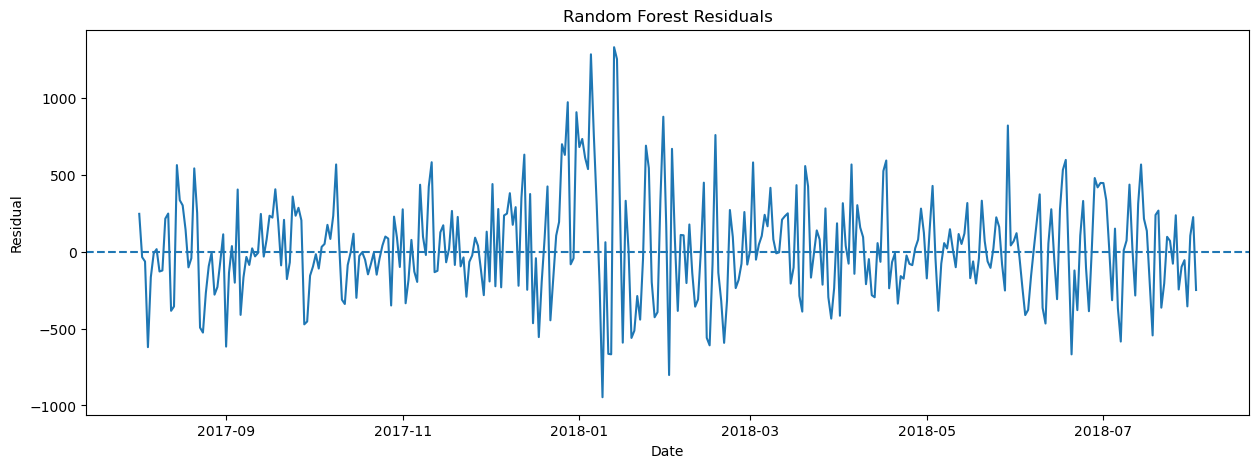

In [128]:
plt.figure(figsize=(15, 5))

plt.plot(
    residuals.index,
    residuals
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Random Forest Residuals"
)

plt.xlabel("Date")
plt.ylabel("Residual")

plt.show()

Residual:

Residual = Actual - Predicted

Ideally, residuals should fluctuate around zero without a strong systematic pattern.

## STEP 75 — Save Random Forest

In [129]:
import joblib

joblib.dump(
    rf_model,
    "random_forest_model.pkl"
)

print("Random Forest model saved.")

Random Forest model saved.


## STEP 76 — 30-Day Future Forecast 

<pre>
We will use the Random Forest model recursively.

That means:

Actual historical data
        ↓
Predict Day 1
        ↓
Use Day 1 prediction as lag
        ↓
Predict Day 2
        ↓
Use Day 2 prediction
        ↓
...
        ↓
30-day forecast 
    </pre>

## STEP 77 — Create Recursive Forecast Function 

In [130]:
def create_features_for_date(history, date):

    temp = history.copy()

    row = {}

    row["year"] = date.year
    row["month"] = date.month
    row["day"] = date.day
    row["dayofweek"] = date.dayofweek
    row["dayofyear"] = date.dayofyear
    row["quarter"] = date.quarter

    row["is_weekend"] = int(
        date.dayofweek >= 5
    )

    row["lag_1"] = temp.iloc[-1]

    row["lag_7"] = temp.iloc[-7]

    row["lag_14"] = temp.iloc[-14]

    row["lag_28"] = temp.iloc[-28]

    row["rolling_mean_7"] = (
        temp.iloc[-7:].mean()
    )

    row["rolling_mean_30"] = (
        temp.iloc[-30:].mean()
    )

    row["rolling_std_7"] = (
        temp.iloc[-7:].std()
    )

    row["dow_sin"] = np.sin(
        2 * np.pi * date.dayofweek / 7
    )

    row["dow_cos"] = np.cos(
        2 * np.pi * date.dayofweek / 7
    )

    row["doy_sin"] = np.sin(
        2 * np.pi * date.dayofyear / 365
    )

    row["doy_cos"] = np.cos(
        2 * np.pi * date.dayofyear / 365
    )

    return pd.DataFrame(
        [row],
        index=[date]
    )

## STEP 78 — Generate 30-Day Forecast 

In [131]:
history = daily["PJMW_MW"].copy()

future_dates = pd.date_range(
    start=daily.index.max() + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

future_predictions = []

for date in future_dates:

    features = create_features_for_date(
        history,
        date
    )

    prediction = rf_model.predict(
        features[features_ml]
    )[0]

    future_predictions.append(
        prediction
    )

    # Add prediction to history
    history.loc[date] = prediction

## STEP 79 — Create Forecast DataFrame 

In [132]:
forecast_30 = pd.DataFrame({

    "Date": future_dates,

    "Predicted_MW": future_predictions

})

forecast_30.set_index(
    "Date",
    inplace=True
)

print(forecast_30)

            Predicted_MW
Date                    
2018-08-03   5696.823113
2018-08-04   5346.217034
2018-08-05   5327.421934
2018-08-06   5810.570670
2018-08-07   5847.781485
2018-08-08   5755.681399
2018-08-09   5717.837075
2018-08-10   5674.383783
2018-08-11   5191.193791
2018-08-12   5165.719861
2018-08-13   5795.211972
2018-08-14   5783.286172
2018-08-15   5714.677018
2018-08-16   5757.457493
2018-08-17   5701.366929
2018-08-18   5232.803693
2018-08-19   5155.358360
2018-08-20   5685.538974
2018-08-21   5853.621541
2018-08-22   5787.817179
2018-08-23   5739.533032
2018-08-24   5688.583417
2018-08-25   5215.076530
2018-08-26   5136.351036
2018-08-27   5662.429485
2018-08-28   5854.987966
2018-08-29   5801.250294
2018-08-30   5719.563418
2018-08-31   5639.367863
2018-09-01   5225.855280


## STEP 80 — Display 30-Day Forecast 

In [133]:
forecast_30.round(2)

,Predicted_MW
Date,
2018-08-03,5696.82
2018-08-04,5346.22
2018-08-05,5327.42
2018-08-06,5810.57
2018-08-07,5847.78
2018-08-08,5755.68
2018-08-09,5717.84
2018-08-10,5674.38
2018-08-11,5191.19


## STEP 81 — Plot 30-Day Forecast 

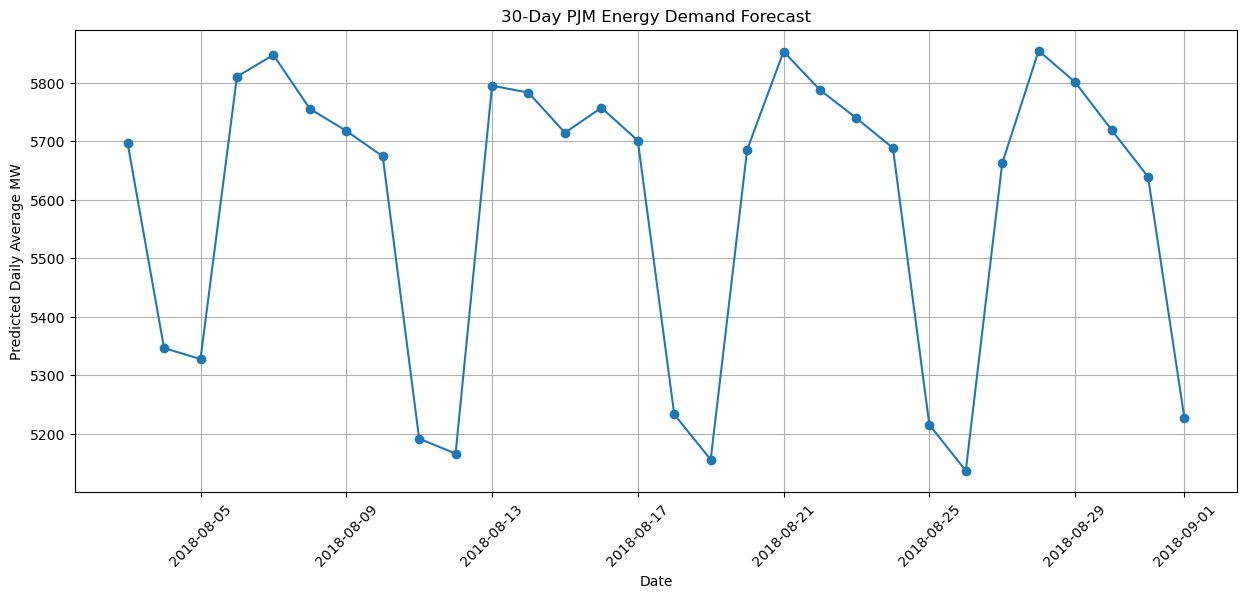

In [134]:
plt.figure(figsize=(15, 6))

plt.plot(
    forecast_30.index,
    forecast_30["Predicted_MW"],
    marker="o"
)

plt.title(
    "30-Day PJM Energy Demand Forecast"
)

plt.xlabel("Date")

plt.ylabel(
    "Predicted Daily Average MW"
)

plt.xticks(rotation=45)

plt.grid()

plt.show()

## STEP 82 — Historical + Future Forecast 

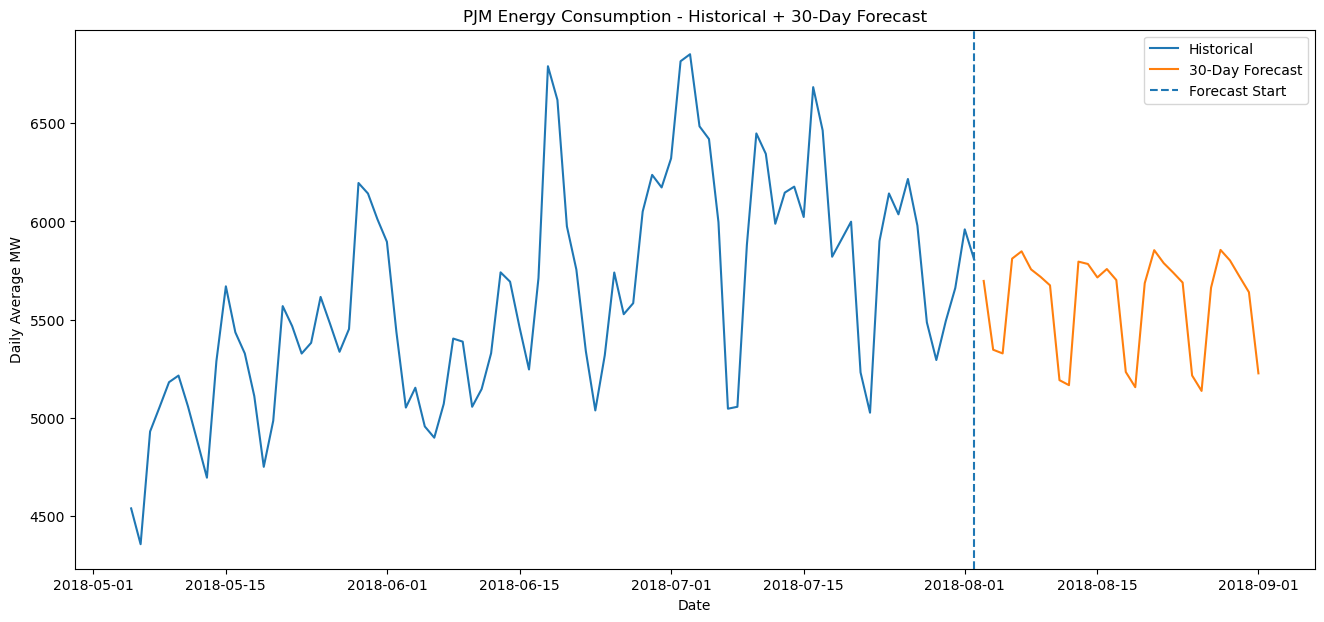

In [135]:
plt.figure(figsize=(16, 7))

# Last 90 historical days
historical = daily.iloc[-90:]

plt.plot(
    historical.index,
    historical["PJMW_MW"],
    label="Historical"
)

plt.plot(
    forecast_30.index,
    forecast_30["Predicted_MW"],
    label="30-Day Forecast"
)

plt.axvline(
    daily.index.max(),
    linestyle="--",
    label="Forecast Start"
)

plt.title(
    "PJM Energy Consumption - Historical + 30-Day Forecast"
)

plt.xlabel("Date")

plt.ylabel(
    "Daily Average MW"
)

plt.legend()

plt.show()

## STEP 83 — Save 30-Day Forecast 

In [136]:
forecast_30.to_csv(
    "30_day_forecast.csv"
)

forecast_30.to_excel(
    "30_day_forecast.xlsx"
)

print("Forecast files saved.")

Forecast files saved.


## STEP 84 — Save XGBoost Too 

In [137]:
joblib.dump(
    xgb_model,
    "xgboost_model.pkl"
)

['xgboost_model.pkl']

## STEP 85 — Save Feature Importance 

In [138]:
importance.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)

## STEP 86 — Save LSTM 

In [139]:
torch.save(
    lstm_model.state_dict(),
    "lstm_state_dict.pt"
)

## STEP 87 — Save GRU 

In [140]:
torch.save(
    gru_model.state_dict(),
    "gru_state_dict.pt"
)

In [141]:
dow = daily["PJMW_MW"].groupby(daily.index.dayofweek).mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(dow.round(0))
print("Weekend vs weekday:", round(
    (daily.loc[daily.index.dayofweek >= 5, "PJMW_MW"].mean()
     / daily.loc[daily.index.dayofweek < 5, "PJMW_MW"].mean() - 1) * 100, 1), "%")

Mon    5701.0
Tue    5802.0
Wed    5803.0
Thu    5781.0
Fri    5687.0
Sat    5294.0
Sun    5149.0
Name: PJMW_MW, dtype: float64
Weekend vs weekday: -9.3 %


In [142]:
df["is_weekend"] = (df.index.dayofweek >= 5).astype(int)

hourly_cmp = df.groupby("is_weekend")["PJMW_MW"].mean()
print("Hourly average demand")
print("Weekday:", round(hourly_cmp[0], 1), "MW")
print("Weekend:", round(hourly_cmp[1], 1), "MW")
print("Difference:", round((hourly_cmp[1] / hourly_cmp[0] - 1) * 100, 1), "%")

daily_avg = df["PJMW_MW"].resample("D").mean().iloc[:-1]
days = daily_avg.index.day_name()
print("\nAverage daily demand by day of week")
print(daily_avg.groupby(days).mean()
      .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
      .round(0))

by_year = daily_avg.groupby(daily_avg.index.year).apply(
    lambda g: (g[g.index.dayofweek >= 5].mean() / g[g.index.dayofweek < 5].mean() - 1) * 100
)
print("\nWeekend vs weekday % by year")
print(by_year.round(1))

Hourly average demand
Weekday: 5754.7 MW
Weekend: 5221.5 MW
Difference: -9.3 %

Average daily demand by day of week
Datetime
Monday       5701.0
Tuesday      5802.0
Wednesday    5803.0
Thursday     5781.0
Friday       5687.0
Saturday     5294.0
Sunday       5149.0
Name: PJMW_MW, dtype: float64

Weekend vs weekday % by year
Datetime
2002   -10.7
2003    -9.3
2004    -9.7
2005    -9.1
2006    -9.8
2007   -10.4
2008    -8.7
2009   -11.0
2010    -9.1
2011    -8.7
2012    -9.5
2013    -9.4
2014   -10.2
2015    -8.1
2016    -8.2
2017    -7.5
2018    -7.7
Name: PJMW_MW, dtype: float64


### Interpretation: Weekday vs Weekend Demand

- **Hourly average:** weekday demand averages **5,754.7 MW** and weekend demand averages **5,221.5 MW**. Weekends use about **9.3% less** electricity.
- **By day of week:** Tuesday to Thursday are the highest (about 5,780–5,800 MW). Monday and Friday are slightly lower (about 5,690–5,700 MW). **Saturday (5,294 MW) and Sunday (5,149 MW)** are clearly the lowest, and Sunday is the lowest day of the week.
- **Consistency over time:** weekend demand is lower than weekday demand in **all 17 years (2002–2018)**, by 7.5% to 11%. This is a stable, long-term pattern, not a one-off.
- **Why:** offices, schools and factories consume less power on weekends, so commercial and industrial load drops while household load only rises a little.
- **Why it matters for modelling:** day of week and the weekend flag are strong predictors. That is why `dayofweek`, `dow_sin`, `dow_cos` and `is_weekend` are included as features, and why the 30-day forecast shows the same weekend dip (about 10% lower).
- **Conclusion:** the weekend-lower-than-weekday result in the forecast matches the real data, so the model has learned a genuine pattern and the result is correct.